In [ ]:
!pip install -q kaggle kagglehub


In [ ]:
!rm -rf ~/.kaggle
!rm -f kaggle.json
!rm -f kaggle*.json


In [ ]:
from google.colab import files
_ = files.upload()  # Yuklenen kaggle.json icerigini hucre ciktisinda gosterme


Saving kaggle.json to kaggle.json


Kaggle kimlik bilgileri guvenlik nedeniyle notebook ciktisindan kaldirildi.

In [ ]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/kaggle.json
!chmod 600 ~/.kaggle/kaggle.json


In [ ]:
import os

BASE_DIR = "/content/datasets"
os.makedirs(BASE_DIR, exist_ok=True)
print("Base dataset klasörü:", BASE_DIR)


Base dataset klasörü: /content/datasets


In [ ]:
!kaggle datasets download -d serenaraju/yawn-eye-dataset-new

import zipfile, os

zip_path = '/content/yawn-eye-dataset-new.zip'
extract_path = '/content/datasets/driver_data'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Ana dataset çıkartıldı!")
for cls in ['yawn', 'no_yawn']:
    path = f'/content/datasets/driver_data/dataset_new/train/{cls}'
    print(f"train/{cls}: {len(os.listdir(path))} dosya")

Dataset URL: https://www.kaggle.com/datasets/serenaraju/yawn-eye-dataset-new
License(s): unknown
100% 161M/161M [00:01<00:00, 143MB/s]

Ana dataset çıkartıldı!
train/yawn: 617 dosya
train/no_yawn: 616 dosya


In [ ]:
import os, shutil, zipfile

!kaggle datasets download -d davidvazquezcic/yawn-dataset

yeni_zip = '/content/yawn-dataset.zip'
yeni_extract = '/content/datasets/yawn_extra'

with zipfile.ZipFile(yeni_zip, 'r') as zip_ref:
    zip_ref.extractall(yeni_extract)

hedef_yawn   = '/content/datasets/driver_data/dataset_new/train/yawn'
hedef_noyawn = '/content/datasets/driver_data/dataset_new/train/no_yawn'

os.makedirs(hedef_yawn, exist_ok=True)
os.makedirs(hedef_noyawn, exist_ok=True)

kaynak_yawn   = '/content/datasets/yawn_extra/yawn'
kaynak_noyawn = '/content/datasets/yawn_extra/no yawn'

kopyalanan_yawn = 0
for dosya in os.listdir(kaynak_yawn):
    if dosya.lower().endswith(('.jpg', '.jpeg', '.png')):
        shutil.copy(os.path.join(kaynak_yawn, dosya),
                    os.path.join(hedef_yawn, 'ex_' + dosya))
        kopyalanan_yawn += 1

kopyalanan_noyawn = 0
for dosya in os.listdir(kaynak_noyawn):
    if dosya.lower().endswith(('.jpg', '.jpeg', '.png')):
        shutil.copy(os.path.join(kaynak_noyawn, dosya),
                    os.path.join(hedef_noyawn, 'ex_' + dosya))
        kopyalanan_noyawn += 1

print(f"✅ Tamamlandı!")
print(f"Toplam yawn: {len(os.listdir(hedef_yawn))}")
print(f"Toplam no_yawn: {len(os.listdir(hedef_noyawn))}")

Dataset URL: https://www.kaggle.com/datasets/davidvazquezcic/yawn-dataset
License(s): CC-BY-NC-SA-4.0
100% 16.9M/16.9M [00:00<00:00, 71.8MB/s]

✅ Tamamlandı!
Toplam yawn: 3145
Toplam no_yawn: 3207


In [ ]:
import os, shutil, random

hedef_train_yawn  = '/content/datasets/driver_data/dataset_new/train/yawn'
hedef_train_noyawn= '/content/datasets/driver_data/dataset_new/train/no_yawn'
hedef_test_yawn   = '/content/datasets/driver_data/dataset_new/test/yawn'
hedef_test_noyawn = '/content/datasets/driver_data/dataset_new/test/no_yawn'

os.makedirs(hedef_test_yawn, exist_ok=True)
os.makedirs(hedef_test_noyawn, exist_ok=True)

# Train'deki ex_ ile başlayan dosyaları bul
yawn_dosyalar   = [f for f in os.listdir(hedef_train_yawn)   if f.startswith('ex_')]
noyawn_dosyalar = [f for f in os.listdir(hedef_train_noyawn) if f.startswith('ex_')]

# %20'sini test'e taşı
yawn_test   = random.sample(yawn_dosyalar,   int(len(yawn_dosyalar)   * 0.2))
noyawn_test = random.sample(noyawn_dosyalar, int(len(noyawn_dosyalar) * 0.2))

for dosya in yawn_test:
    shutil.move(
        os.path.join(hedef_train_yawn, dosya),
        os.path.join(hedef_test_yawn, dosya)
    )

for dosya in noyawn_test:
    shutil.move(
        os.path.join(hedef_train_noyawn, dosya),
        os.path.join(hedef_test_noyawn, dosya)
    )

print(f"Train yawn:    {len(os.listdir(hedef_train_yawn))}")
print(f"Train no_yawn: {len(os.listdir(hedef_train_noyawn))}")
print(f"Test yawn:     {len(os.listdir(hedef_test_yawn))}")
print(f"Test no_yawn:  {len(os.listdir(hedef_test_noyawn))}")

Train yawn:    2640
Train no_yawn: 2689
Test yawn:     611
Test no_yawn:  627


In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
import matplotlib.pyplot as plt

base_dir = '/content/datasets/driver_data/dataset_new'

IMG_SHAPE = 128
BATCH_SIZE = 32

# Yawn için augmentation — preprocess_input
train_yawn_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=25,
    width_shift_range=0.15,
    height_shift_range=0.15,
    shear_range=0.15,
    zoom_range=0.2,
    horizontal_flip=True,
    brightness_range=[0.6, 1.4],
    fill_mode='nearest'
)
val_yawn_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

# Yawn generatorları
train_yawn_generator = train_yawn_datagen.flow_from_directory(
    base_dir + '/train',
    target_size=(IMG_SHAPE, IMG_SHAPE),
    batch_size=BATCH_SIZE,
    classes=['no_yawn', 'yawn'],
    class_mode='binary',
    shuffle=True
)
val_yawn_generator = val_yawn_datagen.flow_from_directory(
    base_dir + '/test',
    target_size=(IMG_SHAPE, IMG_SHAPE),
    batch_size=BATCH_SIZE,
    classes=['no_yawn', 'yawn'],
    class_mode='binary',
    shuffle=False
)
print("Ağız Sınıfları:", train_yawn_generator.class_indices)

Found 5329 images belonging to 2 classes.
Found 1238 images belonging to 2 classes.
Ağız Sınıfları: {'no_yawn': 0, 'yawn': 1}


In [ ]:
import numpy as np
# Generator sıfırla
train_yawn_generator.reset()
print("Yawn train:", train_yawn_generator.n, "görüntü")

Yawn train: 5329 görüntü


In [ ]:
print("Ağız Modeli Sınıf İndeksleri:", train_yawn_generator.class_indices)

Ağız Modeli Sınıf İndeksleri: {'no_yawn': 0, 'yawn': 1}


In [ ]:
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.applications import MobileNetV2

#YAWN MODELİ — güçlendirilmiş head, doğru preprocessing
base_model = MobileNetV2(
    input_shape=(IMG_SHAPE, IMG_SHAPE, 3),
    include_top=False,
    weights='imagenet'
)
base_model.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(512, activation='relu')(x)
x = BatchNormalization()(x)
x = Dropout(0.4)(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.3)(x)
predictions = Dense(1, activation='sigmoid')(x)

yawn_model = Model(inputs=base_model.input, outputs=predictions)
yawn_model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("Model başarıyla oluşturuldu.")
yawn_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Model başarıyla oluşturuldu.


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 64, 64,    │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 64, 64,    │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 64, 64,    │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 64, 64,    │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 64, 64,    │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 64, 64,    │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 64, 64,    │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 64, 64,    │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 64, 64,    │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 64, 64,    │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 64, 64,    │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 65, 65,    │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 32, 32,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 32, 32,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 32, 32,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 32, 32,    │      2,304 │ block_1_depthwis

 Total params: 2,981,697 (11.37 MB)

 Trainable params: 722,689 (2.76 MB)

 Non-trainable params: 2,259,008 (8.62 MB)

Yawn class weights: {0: np.float64(0.9908888062476757), 1: np.float64(1.009280303030303)}

2. Ağız Modeli Eğitiliyor...
Epoch 1/40
167/167 ━━━━━━━━━━━━━━━━━━━━ 0s 265ms/step - accuracy: 0.6758 - loss: 0.6885
Epoch 1: val_accuracy improved from None to 0.88045, saving model to yawn_model_best.h5



Epoch 1: finished saving model to yawn_model_best.h5

Epoch 1: val_accuracy improved from None to 0.88045, saving model to /content/drive/MyDrive/drowsiness_models/yawn_model_best.h5



Epoch 1: finished saving model to /content/drive/MyDrive/drowsiness_models/yawn_model_best.h5
167/167 ━━━━━━━━━━━━━━━━━━━━ 83s 378ms/step - accuracy: 0.7561 - loss: 0.5213 - val_accuracy: 0.8805 - val_loss: 0.2762 - learning_rate: 1.0000e-04
Epoch 2/40
167/167 ━━━━━━━━━━━━━━━━━━━━ 0s 188ms/step - accuracy: 0.8445 - loss: 0.3515
Epoch 2: val_accuracy improved from 0.88045 to 0.88207, saving model to yawn_model_best.h5



Epoch 2: finished saving model to yawn_model_best.h5

Epoch 2: val_accuracy improved from 0.88045 to 0.88207, saving model to /content/drive/MyDrive/drowsiness_models/yawn_model_best.h5



Epoch 2: finished saving model to /content/drive/MyDrive/drowsiness_models/yawn_model_best.h5
167/167 ━━━━━━━━━━━━━━━━━━━━ 33s 200ms/step - accuracy: 0.8478 - loss: 0.3428 - val_accuracy: 0.8821 - val_loss: 0.2424 - learning_rate: 1.0000e-04
Epoch 3/40
167/167 ━━━━━━━━━━━━━━━━━━━━ 0s 231ms/step - accuracy: 0.8617 - loss: 0.3015
Epoch 3: val_accuracy improved from 0.88207 to 0.88691, saving model to yawn_model_best.h5


...


Epoch 17: finished saving model to /content/drive/MyDrive/drowsiness_models/yawn_model_best.h5
167/167 ━━━━━━━━━━━━━━━━━━━━ 31s 186ms/step - accuracy: 0.9221 - loss: 0.1837 - val_accuracy: 0.9394 - val_loss: 0.1652 - learning_rate: 1.0000e-04
Epoch 18/40
167/167 ━━━━━━━━━━━━━━━━━━━━ 0s 175ms/step - accuracy: 0.9185 - loss: 0.1968
Epoch 18: val_accuracy did not improve from 0.93942

Epoch 18: val_accuracy did not improve from 0.93942
167/167 ━━━━━━━━━━━━━━━━━━━━ 31s 182ms/step - accuracy: 0.9195 - loss: 0.1921 - val_accuracy: 0.9281 - val_loss: 0.1769 - learning_rate: 1.0000e-04
Epoch 19/40
167/167 ━━━━━━━━━━━━━━━━━━━━ 0s 172ms/step - accuracy: 0.9194 - loss: 0.1943
Epoch 19: val_accuracy did not improve from 0.93942

Epoch 19: val_accuracy did not improve from 0.93942
167/167 ━━━━━━━━━━━━━━━━━━━━ 30s 179ms/step - accuracy: 0.9171 - loss: 0.1955 - val_accuracy: 0.9338 - val_loss: 0.1772 - learning_rate: 1.0000e-04
Epoch 20/40
167/167 ━━━━━━━━━━━━━━━━━━━━ 0s 178ms/step - accuracy: 0.918


Epoch 20: finished saving model to yawn_model_best.h5

Epoch 20: val_accuracy improved from 0.93942 to 0.94346, saving model to /content/drive/MyDrive/drowsiness_models/yawn_model_best.h5



Epoch 20: finished saving model to /content/drive/MyDrive/drowsiness_models/yawn_model_best.h5
167/167 ━━━━━━━━━━━━━━━━━━━━ 32s 190ms/step - accuracy: 0.9159 - loss: 0.1839 - val_accuracy: 0.9435 - val_loss: 0.1700 - learning_rate: 1.0000e-04
Epoch 21/40
167/167 ━━━━━━━━━━━━━━━━━━━━ 0s 172ms/step - accuracy: 0.9227 - loss: 0.1769
Epoch 21: ReduceLROnPlateau reducing learning rate to 2.9999999242136255e-05.

Epoch 21: val_accuracy improved from 0.94346 to 0.94588, saving model to yawn_model_best.h5



Epoch 21: finished saving model to yawn_model_best.h5

Epoch 21: val_accuracy improved from 0.94346 to 0.94588, saving model to /content/drive/MyDrive/drowsiness_models/yawn_model_best.h5



Epoch 21: finished saving model to /content/drive/MyDrive/drowsiness_models/yawn_model_best.h5
167/167 ━━━━━━━━━━━━━━━━━━━━ 31s 183ms/step - accuracy: 0.9210 - loss: 0.1862 - val_accuracy: 0.9459 - val_loss: 0.1654 - learning_rate: 1.0000e-04
Epoch 22/40
167/167 ━━━━━━━━━━━━━━━━━━━━ 0s 179ms/step - accuracy: 0.9276 - loss: 0.1809
Epoch 22: val_accuracy did not improve from 0.94588

Epoch 22: val_accuracy did not improve from 0.94588
167/167 ━━━━━━━━━━━━━━━━━━━━ 31s 186ms/step - accuracy: 0.9293 - loss: 0.1708 - val_accuracy: 0.9338 - val_loss: 0.1742 - learning_rate: 3.0000e-05
Epoch 23/40
167/167 ━━━━━━━━━━━━━━━━━━━━ 0s 173ms/step - accuracy: 0.9266 - loss: 0.1762
Epoch 23: val_accuracy did not improve from 0.94588

Epoch 23: val_accuracy did not improve from 0.94588
167/167 ━━━━━━━━━━━━━━━━━━━━ 30s 180ms/step - accuracy: 0.9268 - loss: 0.1702 - val_accuracy: 0.9289 - val_loss: 0.1802 - learning_rate: 3.0000e-05
Epoch 24/40
167/167 ━━━━━━━━━━━━━━━━━━━━ 0s 175ms/step - accuracy: 0.917

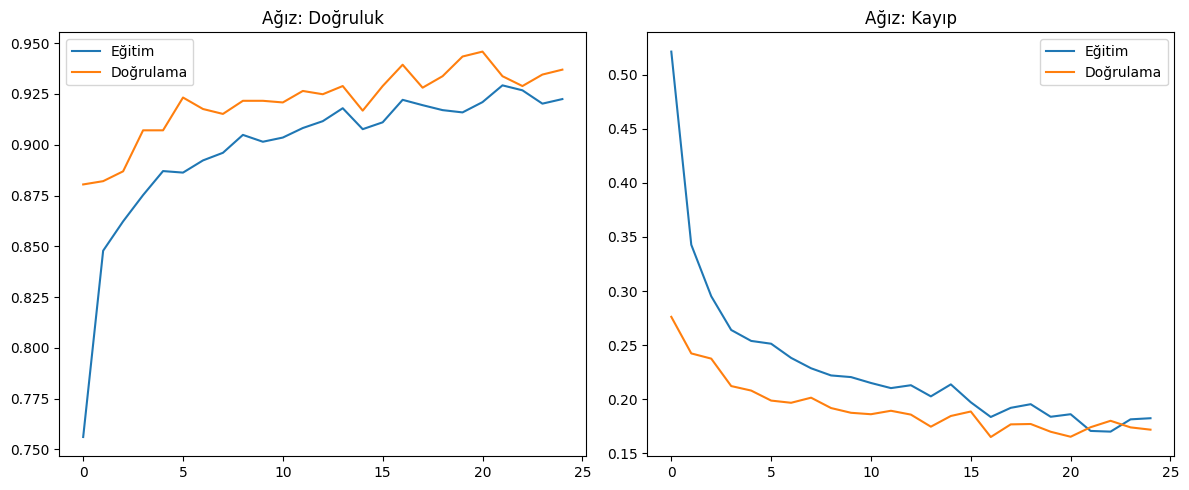

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

def get_callbacks(model_name):
    return [
        EarlyStopping(monitor='val_loss', patience=8,
                      restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor='val_loss', factor=0.3,
                          patience=4, min_lr=1e-6, verbose=1),
        ModelCheckpoint(f'{model_name}_best.h5',
                        monitor='val_accuracy',
                        save_best_only=True, verbose=1),
        ModelCheckpoint(f'/content/drive/MyDrive/drowsiness_models/{model_name}_best.h5',
                        monitor='val_accuracy',
                        save_best_only=True, verbose=1)
    ]

# Class weight
yawn_weights = compute_class_weight('balanced',
                                    classes=np.array([0, 1]),
                                    y=train_yawn_generator.classes)
yawn_class_weight = dict(enumerate(yawn_weights))
print("Yawn class weights:", yawn_class_weight)

# YAWN EĞİTİMİ
print("\n2. Ağız Modeli Eğitiliyor...")
yawn_history = yawn_model.fit(
    train_yawn_generator,
    epochs=40,
    validation_data=val_yawn_generator,
    class_weight=yawn_class_weight,
    callbacks=get_callbacks('yawn_model')
)

# GRAFİKLER
plt.figure(figsize=(12, 5))
plt.subplot(1,2,1); plt.plot(yawn_history.history['accuracy'], label='Eğitim'); plt.plot(yawn_history.history['val_accuracy'], label='Doğrulama'); plt.title('Ağız: Doğruluk'); plt.legend()
plt.subplot(1,2,2); plt.plot(yawn_history.history['loss'], label='Eğitim'); plt.plot(yawn_history.history['val_loss'], label='Doğrulama'); plt.title('Ağız: Kayıp'); plt.legend()
plt.tight_layout(); plt.show()

In [ ]:
from tensorflow.keras.models import load_model
yawn_model = load_model('yawn_model_best.h5')
print("En iyi model yüklendi.")

En iyi model yüklendi.


Ağız Modeli için tahminler yapılıyor...
39/39 ━━━━━━━━━━━━━━━━━━━━ 11s 146ms/step


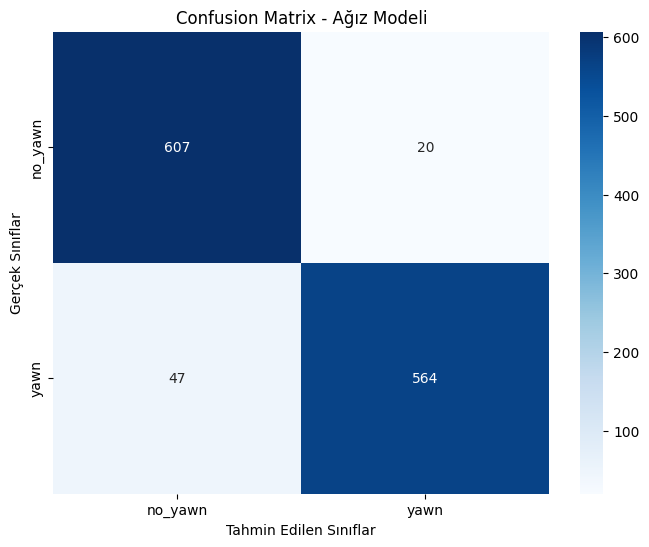


--- Ağız Modeli Sınıflandırma Raporu ---

              precision    recall  f1-score   support

     no_yawn       0.93      0.97      0.95       627
        yawn       0.97      0.92      0.94       611

    accuracy                           0.95      1238
   macro avg       0.95      0.95      0.95      1238
weighted avg       0.95      0.95      0.95      1238



In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

def plot_cm(model, generator, title):
    generator.reset()
    print(f"{title} için tahminler yapılıyor...")
    Y_pred = model.predict(generator)
    # Binary classification olduğu için 0.5 eşik değerine göre sınıfa çeviriyoruz
    y_pred = (Y_pred > 0.5).astype(int).flatten()
    y_true = generator.classes
    class_labels = list(generator.class_indices.keys())

    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_labels,
                yticklabels=class_labels)
    plt.title(f'Confusion Matrix - {title}')
    plt.ylabel('Gerçek Sınıflar')
    plt.xlabel('Tahmin Edilen Sınıflar')
    plt.show()

    print(f"\n--- {title} Sınıflandırma Raporu ---\n")
    print(classification_report(y_true, y_pred, target_names=class_labels))

# matrisleri çizdir
plot_cm(yawn_model, val_yawn_generator, "Ağız Modeli")

In [ ]:
import tensorflow as tf
from google.colab import files
from tensorflow.keras.models import load_model

# En iyi modeli yükle
yawn_model = load_model('yawn_model_best.h5')

print(" Model yüklendi.")
print("Yawn modeli:", yawn_model.input_shape)
print("Modell kaydediliyor...")

# YAWN MODELİ kaydet
yawn_model.save('yawn_model_final.h5')
converter_yawn = tf.lite.TFLiteConverter.from_keras_model(yawn_model)
converter_yawn.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_yawn = converter_yawn.convert()
with open('yawn_model_opt.tflite', 'wb') as f:
    f.write(tflite_yawn)
print("✅ Yawn modeli kaydedildi.")

print("\nİndirme başlıyor...")
files.download('yawn_model_opt.tflite')
files.download('yawn_model_final.h5')

 Model yüklendi.
Yawn modeli: (None, 128, 128, 3)
Modell kaydediliyor...
Saved artifact at '/tmp/tmp2op2ahmv'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name='input_layer')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  134194761224016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134194761225552: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134194761225360: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134194761224976: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134194761226320: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134194761224784: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134194761225744: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134194761225936: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134194761223632: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134194761227

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>